# ClientCo — Qualité des données et vue d'ensemble de l'activité

**Objectif du notebook** : comprendre le dataset transactionnel du use case *Prévention du churn* (UC n°1 de la priorisation d'équipe) **avant** de modéliser : peut-on lui faire confiance (Q1), et à quoi ressemble l'activité (Q2) ?

## Ce que disent les documents du cas (synthèse)

| Sujet | Ce qu'on retient | Source |
|---|---|---|
| Entreprise | Distributeur B2B de matériaux de construction, ~15,5 Md de CA, >1 000 agences, >15 pays, >450 k clients actifs, ~200 commerciaux, marge brute ≈ 25 %. Agences = 60 % des ventes, online ≈ 0. | Key Facts, Financials |
| Sponsor | La CDO (arrivée il y a 3 mois) veut une victoire rapide pour convaincre le CEO. Elle juge le churn *faisable* (données de ventes accessibles, peu d'effectifs) et évoque **+1 % de revenu**. | CDO |
| Soutiens | Commercial Director : « impact financier majeur ». Head of Sales : « hot topic depuis des années, jamais de solution efficace », mesure difficile. Benchmark OffSupp : churn = *quick win*, mais **l'adoption par les équipes locales est le vrai défi**. | Interviews |
| Scepticisme | Sales Manager : « le churn est imprévisible, la data est trop réductrice » — mais prêt à essayer. CRM mal rempli. | Sales Manager |
| Clients | Base très hétérogène : institutions publiques (appels d'offres, action commerciale quasi impossible), acheteurs occasionnels, PME régulières, clients sous contrat long terme, grands comptes gérés centralement. | Head of Sales |
| Causes citées | Ruptures de stock et délais de livraison = **1res raisons de départ** (≈ 50 M de pertes liées aux ruptures). | Supply Chain |
| Leviers d'action | Visite : efficace mais ~3 h + 1 h de suivi. Téléphone : « le meilleur » (efficace, peu coûteux). E-mail : gratuit mais inefficace hors clients très actifs. | Sales Manager, Head of Sales |
| Données | **Uniquement des transactions** (8 colonnes), sous-ensemble des agences et clients. Aucune donnée qualitative / comportementale client. | Data team |
| Calendrier | Case Team Meeting le 20/11 ; modèle à rendre le 26/11 à 12h ; passage devant le CEO le 27/11. | Brief |

## Carte des notebooks

| Notebook | Contenu |
|---|---|
| `01_data_quality_and_activity_overview` | Qualité des données, vue d'ensemble de l'activité (Q1, Q2) |
| `02_clients_rhythm_and_churn_definition` | Qui sont les clients, rythme d'achat, définition du « perdu », CA en jeu (Q3 à Q5) |
| `03_churn_drivers_early_signals_baseline` | Cohortes, où se concentre le churn, signaux avant-coureurs, score à battre (Q6 à Q9) |
| `04_churn_scope_total_vs_partial` | Périmètre du modèle : churn total ou partiel, segments (Q9 bis) |
| `05_label_test_and_list_allocation` | Test des deux labels, marge, répartition de K (Q9 ter) |
| `06_label_horizon_calibration` | Horizon du label d'entraînement : 41 règles |
| `07_realized_revenue_loss` | Perte de CA réellement subie, décote du churn total |
| `08_label_rolling_backtest` | Comparaison des labels A et B en plan glissant |

Les décisions finales sont dans `docs/modelisation.md`. Dates d'origine du dataset (22/09/2022 au 22/09/2024).

> **Conventions** : « M » = millions dans la devise du dataset (non précisée : Key Facts parle de $, Financials d'EUR). *Jour d'achat* = couple (client, date_order) — le dataset n'a pas d'identifiant de commande (définition précisée plus bas).

> **Définition du jour d'achat dans ce notebook.** Les notebooks 01 à 03 gardent la définition de l'exploration (ligne de vente strictement positive, `rev_pos`) ; à partir du notebook 04, le jour d'achat est le CA net des retours du jour > 0,01 € (décision du 24/11 : 118 009 clients au lieu de 119 656, CA de référence −6 %). Les conclusions de ces trois notebooks ne changent pas ; les décisions de périmètre et de label s'appuient sur les notebooks 04 à 08.

## 0. Setup

Le CSV fait **4,2 Go / 63 M de lignes** : impossible à charger dans pandas sur un laptop. On utilise **DuckDB** : conversion unique en Parquet (~1 min, colonnée et compressée), puis on agrège en SQL et on ne rapatrie dans pandas que de petites tables pour tracer.

In [1]:
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 50, "display.width", 200, "display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV = next((p for p in (ROOT / "data" / "dataset_sales_2026.csv", ROOT / "dataset_sales_2026.csv") if p.exists()), ROOT / "dataset_sales_2026.csv")
PARQUET = ROOT / "data" / "sales.parquet"

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
(ROOT / "data").mkdir(exist_ok=True)
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql: str) -> pd.DataFrame:
    """Run a SQL query and return a pandas DataFrame."""
    return con.execute(sql).fetchdf()


if not PARQUET.exists():
    t0 = time.time()
    con.execute(f"""
        COPY (SELECT * FROM read_csv('{CSV}', delim=';', header=true, columns={{
            'date_order':'DATE','date_invoice':'DATE','product_id':'BIGINT','client_id':'BIGINT',
            'sales_net':'DOUBLE','quantity':'DOUBLE','order_channel':'VARCHAR','branch_id':'BIGINT'}}))
        TO '{PARQUET}' (FORMAT parquet, COMPRESSION zstd)""")
    print(f"CSV -> Parquet en {time.time() - t0:.0f}s")

con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
q("SELECT * FROM sales LIMIT 5")

,date_order,date_invoice,product_id,client_id,sales_net,quantity,order_channel,branch_id
0,2022-09-25,2022-09-25,2376333,188502,155.443,3.000,online,2732
1,2022-09-25,2022-09-25,2520527,835089,16.394,3.000,at the store,10279
2,2022-09-25,2022-09-25,2536756,1977896,365.766,21.000,online,6184
3,2022-09-25,2022-09-25,3028673,598816,8.599,201.000,at the store,4200
4,2022-09-25,2022-09-25,203377,2086861,"1,093.374",3.000,by phone,7051


### Paramètres de la « photo » (modifiables)

Pour parler de churn il faut une **date d'observation T** : on regarde le passé (< T) pour décrire un client, et le futur (≥ T) pour savoir s'il est parti.
- `BASE_DAYS` : population suivie = clients ayant acheté au moins une fois dans les `BASE_DAYS` derniers jours avant T.
- `HORIZON` : un client est *churné* s'il n'achète plus pendant `HORIZON` jours après T.

Le dataset s'arrête le 22/09/2024 ; la dernière photo possible avec 180 jours d'horizon est donc le 22/03/2024. La section 4 justifie ces choix.

In [2]:
T_SNAP = "2024-03-22"   # date de la photo principale
BASE_DAYS = 180         # population = clients actifs dans les 180 derniers jours
HORIZON = 180           # churn = aucun achat pendant les 180 jours suivants
N_REPS = 200            # nombre de commerciaux (Head of Sales)

### Style graphique
Palette catégorielle validée (ordre fixe : une couleur = une entité), rampe bleue pour les magnitudes, gris neutres pour la structure, orange pour « ce qui alerte ». Fond clair pour que les figures restent lisibles quel que soit le thème de l'éditeur.

In [3]:
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ)
NEUTRAL = "#b9b8b0"

# Une couleur par canal, identique dans tout le notebook
CHANNEL_COLOR = {"by phone": C["orange"], "at the store": C["blue"], "online": C["aqua"],
                 "during the visit of a sales rep": C["yellow"], "other": C["magenta"]}
CHANNEL_LABEL = {"by phone": "Téléphone", "at the store": "En agence", "online": "En ligne",
                 "during the visit of a sales rep": "Visite commercial", "other": "Autre"}

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "lines.linewidth": 2, "figure.dpi": 110, "legend.frameon": False, "legend.fontsize": 9,
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
})


def headline(fig, title, sub=None):
    """Action title (the takeaway) + optional muted subtitle, left-aligned above the figure."""
    h = fig.get_figheight()
    fig.text(0.005, 1 + (0.30 if sub else 0.12) / h, title, fontsize=13, fontweight="bold", color=INK, ha="left", va="bottom")
    if sub:
        fig.text(0.005, 1 + 0.08 / h, sub, fontsize=9.5, color=INK2, ha="left", va="bottom")


def fmt_m(x, _=None):
    return f"{x / 1e6:,.0f}"


def pct_axis(ax, axis="y", decimals=0):
    f = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)


def label_end(ax, x, y, text, dx=6, **kw):
    """Direct label at the end of a line (secondary ink, never the series colour)."""
    ax.annotate(text, (x, y), xytext=(dx, 0), textcoords="offset points", va="center", color=INK2, fontsize=9, **kw)


def pct(x, d=1):
    return f"{100 * x:.{d}f} %"

## 1. Qualité et structure des données

**Question Q1** — avant toute analyse de churn, on vérifie que la matière première tient la route. Un client « inactif » peut n'être qu'un artefact de données (retours, trous de calendrier, dates décalées).

In [4]:
kpi = q("""
SELECT count(*)                                  AS lignes,
       count(DISTINCT client_id)                 AS clients,
       count(DISTINCT product_id)                AS produits,
       count(DISTINCT branch_id)                 AS agences,
       min(date_order)                           AS date_order_min,
       max(date_order)                           AS date_order_max,
       min(date_invoice)                         AS date_invoice_min,
       max(date_invoice)                         AS date_invoice_max,
       sum(sales_net)                            AS ca_net,
       sum(greatest(sales_net, 0))               AS ca_positif,
       sum(least(sales_net, 0))                  AS retours
FROM sales""").iloc[0]

quality = q("""
SELECT
  count(*) FILTER (WHERE sales_net < 0)                          AS lignes_negatives,
  count(*) FILTER (WHERE sales_net = 0)                          AS lignes_nulles,
  count(*) FILTER (WHERE date_invoice IS NULL)                   AS facture_manquante,
  count(*) FILTER (WHERE date_invoice < date_order)              AS facture_avant_commande,
  count(*) FILTER (WHERE date_invoice > date_order)              AS facture_apres_commande,
  count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) > 30)  AS facture_plus_30j,
  count(*) FILTER (WHERE date_invoice > DATE '2024-09-22')       AS facture_apres_fin_periode,
  min(quantity)                                                  AS quantite_min,
  quantile_cont(quantity, 0.5)                                   AS quantite_mediane,
  quantile_cont(sales_net, 0.5) FILTER (WHERE sales_net > 0)     AS ligne_mediane
FROM sales""").iloc[0]
n = kpi["lignes"]

print(f"Période de commande  : {kpi['date_order_min']:%d/%m/%Y} -> {kpi['date_order_max']:%d/%m/%Y}  (2 ans exactement)")
print(f"Période de facture   : {kpi['date_invoice_min']:%d/%m/%Y} -> {kpi['date_invoice_max']:%d/%m/%Y}  (déborde largement)")
print(f"Volumétrie           : {n:,.0f} lignes · {kpi['clients']:,.0f} clients · {kpi['produits']:,.0f} produits · {kpi['agences']:,.0f} agences")
print(f"CA net / positif     : {kpi['ca_net'] / 1e9:,.2f} Md / {kpi['ca_positif'] / 1e9:,.2f} Md  (retours = {kpi['retours'] / 1e6:,.0f} M, {abs(kpi['retours']) / kpi['ca_positif']:.1%} du CA positif)")
print(f"Lignes < 0 / = 0     : {quality['lignes_negatives'] / n:.1%} / {quality['lignes_nulles'] / n:.1%}")
print(f"Facture ≠ commande   : {quality['facture_apres_commande'] / n:.1%} facturées après la commande ; {quality['facture_plus_30j'] / n:.1%} à plus de 30 jours ; {quality['facture_avant_commande']:,.0f} avant la commande")
print(f"Quantité             : min {quality['quantite_min']:.0f} (jamais < 3), médiane {quality['quantite_mediane']:.0f} · ligne médiane {quality['ligne_mediane']:.0f}")

Période de commande  : 22/09/2022 -> 22/09/2024  (2 ans exactement)
Période de facture   : 12/10/2021 -> 13/07/2026  (déborde largement)
Volumétrie           : 63,319,315 lignes · 170,589 clients · 607,418 produits · 582 agences
CA net / positif     : 9.37 Md / 9.94 Md  (retours = -577 M, 5.8% du CA positif)
Lignes < 0 / = 0     : 3.8% / 3.8%
Facture ≠ commande   : 29.2% facturées après la commande ; 4.1% à plus de 30 jours ; 99 avant la commande
Quantité             : min 3 (jamais < 3), médiane 5 · ligne médiane 52


**À retenir**
- Les dates de commande couvrent bien **2 ans pile** (22/09/2022 → 22/09/2024) alors que le fichier s'appelle `…_2026.csv` : le décalage de +5 ans prévu dans `exploratory_and_data_update.ipynb` n'est **pas** appliqué dans ce fichier. À clarifier avec l'équipe pour ne pas mélanger les années dans le deck.
- ~4 % de lignes **négatives** (retours / avoirs) et ~4 % de lignes à **zéro** : une ligne négative n'est pas un achat. Un client dont la dernière « activité » est un avoir est en réalité déjà parti.
- `date_invoice` est **bruité** (jusqu'en 2026, 29 % de lignes facturées après la commande) : on prendra `date_order` comme date d'activité.
- La quantité n'est jamais < 3, même pour les lignes négatives : la quantité ne signale pas les retours, le signe de `sales_net` oui.

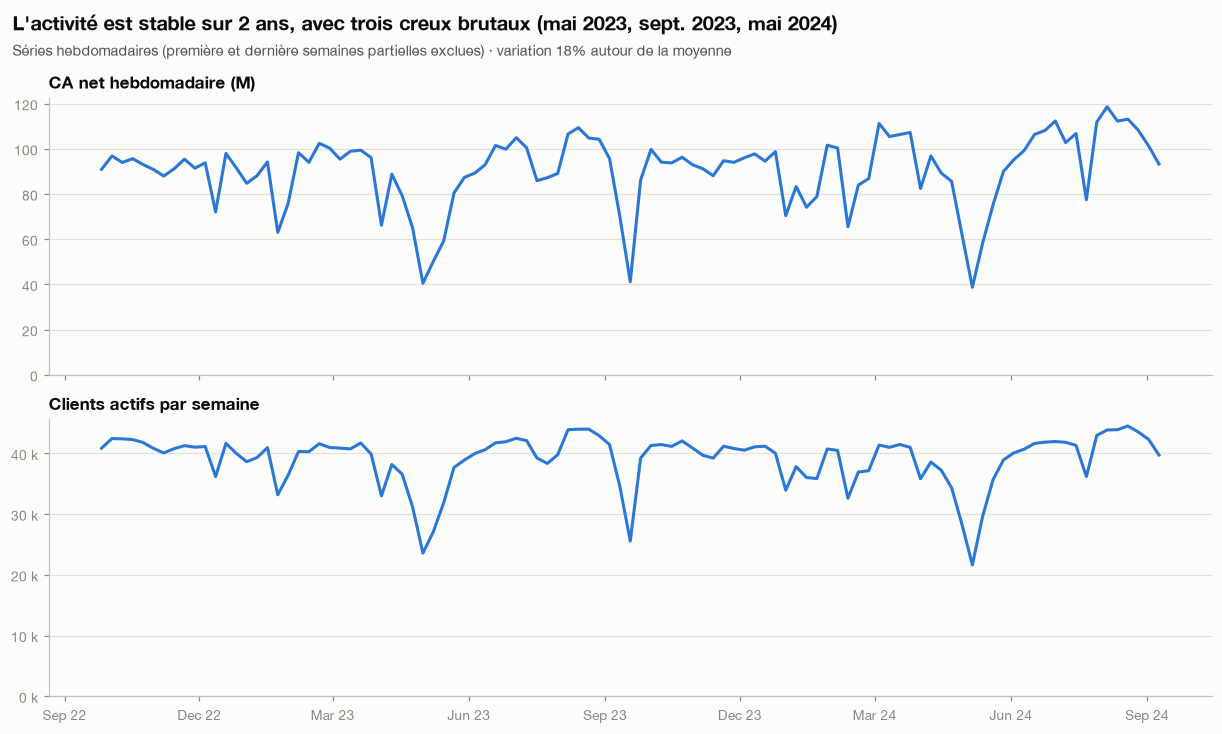

In [5]:
weekly = q("""
SELECT date_trunc('week', date_order) AS week, count(*) AS lignes, sum(sales_net) AS ca,
       count(DISTINCT client_id) AS clients
FROM sales GROUP BY 1 ORDER BY 1""")
weekly = weekly.iloc[1:-1]  # first and last weeks are partial

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].plot(weekly["week"], weekly["ca"], color=C["blue"])
axes[0].set_title("CA net hebdomadaire (M)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_m))
axes[1].plot(weekly["week"], weekly["clients"], color=C["blue"])
axes[1].set_title("Clients actifs par semaine")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} k"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
for ax in axes:
    ax.set_ylim(bottom=0)
cv = weekly["ca"].std() / weekly["ca"].mean()
headline(fig, "L'activité est stable sur 2 ans, avec trois creux brutaux (mai 2023, sept. 2023, mai 2024)",
         f"Séries hebdomadaires (première et dernière semaines partielles exclues) · variation {cv:.0%} autour de la moyenne")
plt.show()

Le calendrier est **continu** (731 jours, aucun trou) mais trois **creux brutaux** divisent l'activité par ~2 : semaines du **1er et 8 mai 2023**, du **18 septembre 2023** et du **6 mai 2024** (jours fériés en France pour mai ; septembre 2023 est inexpliqué — à demander au client). Ils comptent pour le churn : un client qui n'achète pas pendant un creux n'est pas forcément perdu. Regardons aussi le profil par jour de semaine :

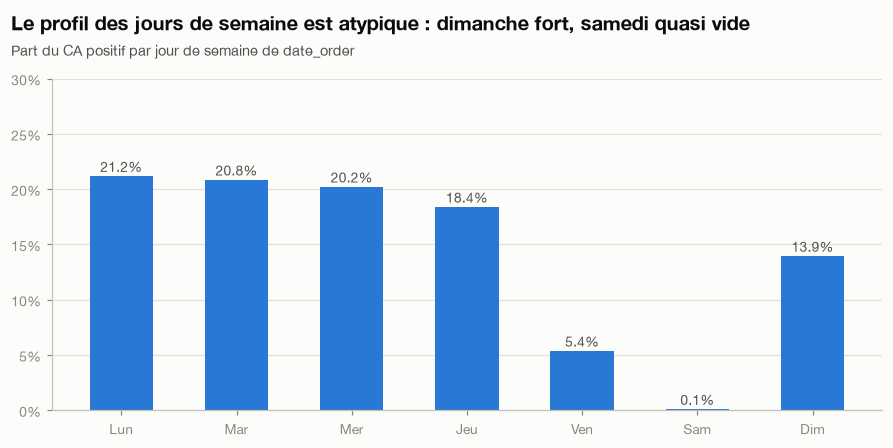

In [6]:
dow = q("""
SELECT isodow(date_order) AS dow, count(*) AS lignes, sum(greatest(sales_net, 0)) AS ca
FROM sales GROUP BY 1 ORDER BY 1""")
labels = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
ax.bar(dow["dow"], dow["ca"] / dow["ca"].sum(), width=0.55, color=C["blue"])
for x, v in zip(dow["dow"], dow["ca"] / dow["ca"].sum()):
    ax.text(x, v + 0.004, f"{v:.1%}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(dow["dow"], labels)
pct_axis(ax)
ax.set_ylim(0, 0.3)
headline(fig, "Le profil des jours de semaine est atypique : dimanche fort, samedi quasi vide",
         "Part du CA positif par jour de semaine de date_order")
plt.show()

Pour un distributeur B2B on attendrait des ventes du lundi au vendredi. Ici le **dimanche pèse ~14 % et le samedi ~0 %** : les dates ont très probablement été **décalées / anonymisées**. Conséquence : ne **pas** construire de variable « jour de semaine » ; les mois et les écarts entre dates restent exploitables.

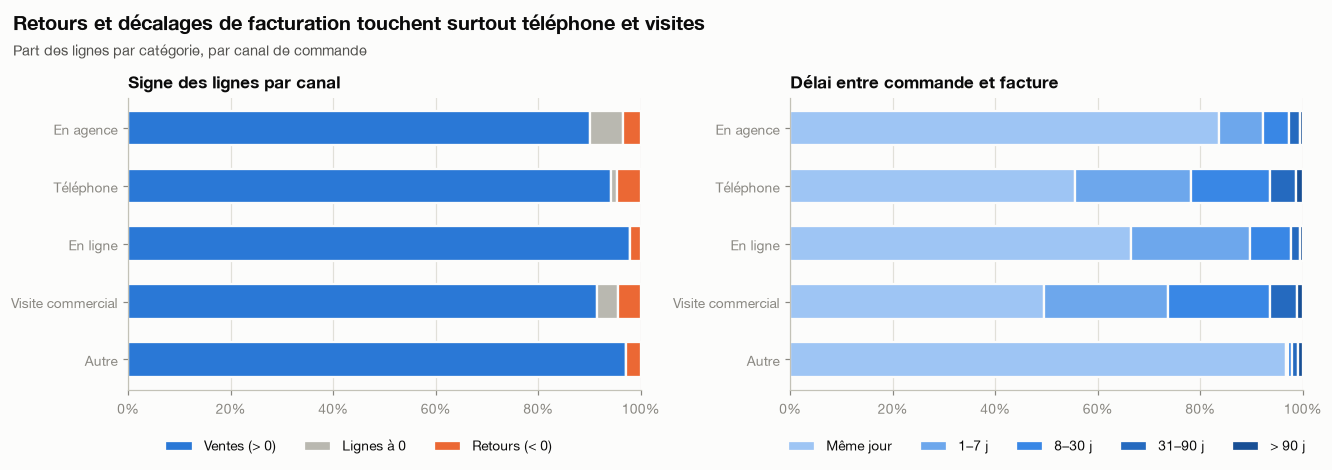

In [7]:
sign_ch = q("""
SELECT order_channel, count(*) FILTER (WHERE sales_net > 0) AS pos, count(*) FILTER (WHERE sales_net = 0) AS zero,
       count(*) FILTER (WHERE sales_net < 0) AS neg
FROM sales GROUP BY 1""").set_index("order_channel")
lag = q("""
SELECT order_channel,
       count(*) FILTER (WHERE date_invoice <= date_order)                                    AS same_day,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) BETWEEN 1 AND 7)    AS d1_7,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) BETWEEN 8 AND 30)   AS d8_30,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) BETWEEN 31 AND 90)  AS d31_90,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) > 90)               AS d90p
FROM sales GROUP BY 1""").set_index("order_channel")
order = ["at the store", "by phone", "online", "during the visit of a sales rep", "other"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
# left: sign of lines per channel
share = sign_ch.loc[order].div(sign_ch.loc[order].sum(axis=1), axis=0)
y = np.arange(len(order))[::-1]
left = np.zeros(len(order))
for col, colr, lab in [("pos", C["blue"], "Ventes (> 0)"), ("zero", NEUTRAL, "Lignes à 0"), ("neg", C["orange"], "Retours (< 0)")]:
    axes[0].barh(y, share[col], left=left, color=colr, height=0.6, label=lab, edgecolor=SURF, linewidth=1.5)
    left += share[col].to_numpy()
axes[0].set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(axes[0], "x")
axes[0].set_xlim(0, 1)
axes[0].grid(axis="x")
axes[0].grid(axis="y", visible=False)
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.12))
axes[0].set_title("Signe des lignes par canal")
# right: invoice lag
shl = lag.loc[order].div(lag.loc[order].sum(axis=1), axis=0)
left = np.zeros(len(order))
for col, colr, lab in zip(["same_day", "d1_7", "d8_30", "d31_90", "d90p"], SEQ[1:6], ["Même jour", "1–7 j", "8–30 j", "31–90 j", "> 90 j"]):
    axes[1].barh(y, shl[col], left=left, color=colr, height=0.6, label=lab, edgecolor=SURF, linewidth=1.5)
    left += shl[col].to_numpy()
axes[1].set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(axes[1], "x")
axes[1].set_xlim(0, 1)
axes[1].grid(axis="x")
axes[1].grid(axis="y", visible=False)
axes[1].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
axes[1].set_title("Délai entre commande et facture")
headline(fig, "Retours et décalages de facturation touchent surtout téléphone et visites",
         "Part des lignes par catégorie, par canal de commande")
plt.show()

Le **retard de facturation** (jusqu'à 3 ans) est massif pour le téléphone et la visite commerciale (~45-50 % des lignes facturées après la commande) et rare en agence : c'est peut-être un proxy de **commandes livrées en différé** (ruptures, délais — les 1res causes de départ selon la Supply Chain). On le testera comme signal dans `03_churn_drivers_early_signals_baseline` (section 3).

### Décisions de nettoyage retenues pour la suite

| Décision | Raison |
|---|---|
| Date d'activité = `date_order` | `date_invoice` déborde jusqu'en 2026 |
| **Jour d'achat** = (client, date_order) avec ventes positives > 0 | pas d'id de commande ; les jours avec seulement des avoirs ne sont pas des achats |
| Les retours restent dans les CA nets mais comptent comme **signal**, pas comme activité | un avoir ≠ réengagement |
| Pas de variable jour-de-semaine | dates décalées |
| 1 seule ligne dupliquée : ignorée | négligeable |

In [8]:
# Daily client x day table (one pass over the 63M lines), then purchase days only.
t0 = time.time()
con.execute("""
CREATE OR REPLACE TABLE cd AS
SELECT client_id, date_order AS d,
       sum(sales_net)                                   AS rev_net,
       sum(greatest(sales_net, 0))                      AS rev_pos,
       sum(least(sales_net, 0))                         AS rev_neg,
       count(*)                                         AS n_lines,
       count(DISTINCT product_id)                       AS n_prod,
       arg_max(branch_id, greatest(sales_net, 0))       AS branch_id,
       arg_max(order_channel, greatest(sales_net, 0))   AS channel,
       avg(least(greatest(date_diff('day', date_order, date_invoice), 0), 365)) AS lag_mean
FROM sales GROUP BY client_id, date_order""")
con.execute("CREATE OR REPLACE TABLE bd AS SELECT * FROM cd WHERE rev_pos > 0")
cnt = q("SELECT (SELECT count(*) FROM cd) AS client_days, (SELECT count(*) FROM bd) AS purchase_days").iloc[0]
print(f"{cnt['client_days']:,.0f} (client, jour) · dont {cnt['purchase_days']:,.0f} jours d'achat · construit en {time.time() - t0:.0f}s")

7,955,289 (client, jour) · dont 7,953,336 jours d'achat · construit en 16s


### Distribution des montants et quantités
Les lignes sont **extrêmement asymétriques** : on trace en échelle log.

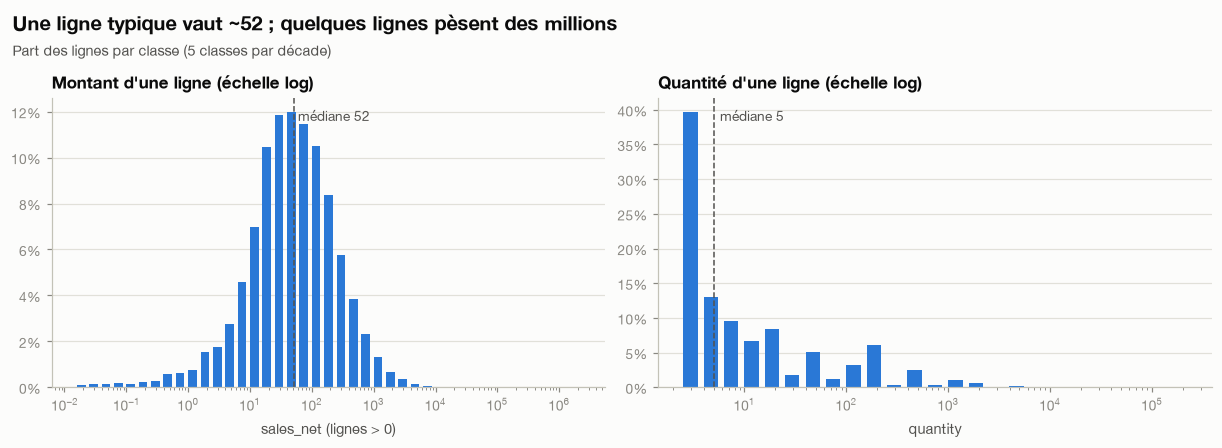

In [9]:
bins_sales = q("""
SELECT floor(log10(sales_net) * 5) / 5 AS b, count(*) AS n FROM sales WHERE sales_net > 0 GROUP BY 1 ORDER BY 1""")
bins_qty = q("SELECT floor(log10(quantity) * 5) / 5 AS b, count(*) AS n FROM sales GROUP BY 1 ORDER BY 1")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
for ax, d, ttl, med in [(axes[0], bins_sales, "Montant d'une ligne (échelle log)", quality["ligne_mediane"]),
                        (axes[1], bins_qty, "Quantité d'une ligne (échelle log)", quality["quantite_mediane"])]:
    ax.bar(10 ** d["b"], d["n"] / d["n"].sum(), width=10 ** d["b"] * 0.38, color=C["blue"], align="edge")
    ax.set_xscale("log")
    pct_axis(ax)
    ax.axvline(med, color=INK2, lw=1, ls="--")
    ax.text(med * 1.15, ax.get_ylim()[1] * 0.92, f"médiane {med:,.0f}", color=INK2, fontsize=9)
    ax.set_title(ttl)
axes[0].set_xlabel("sales_net (lignes > 0)")
axes[1].set_xlabel("quantity")
headline(fig, f"Une ligne typique vaut ~{quality['ligne_mediane']:,.0f} ; quelques lignes pèsent des millions",
         "Part des lignes par classe (5 classes par décade)")
plt.show()

## 2. Vue d'ensemble de l'activité

**Question Q2** — où se fait le chiffre d'affaires ? Cela conditionne les **canaux d'action** possibles pour une campagne de rétention.

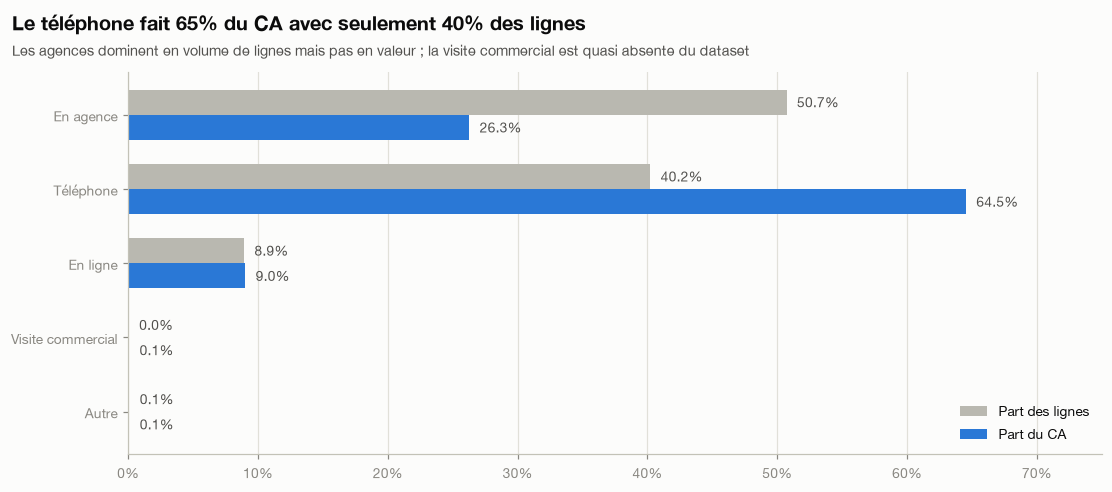

,clients,part_clients,ca_par_ligne
En agence,146857,0.861,81.366
Téléphone,135602,0.795,252.016
En ligne,21352,0.125,158.744
Visite commercial,1203,0.007,266.992
Autre,8811,0.052,156.407


In [10]:
ch = q("""
SELECT order_channel, count(*) AS lignes, sum(greatest(sales_net, 0)) AS ca, count(DISTINCT client_id) AS clients
FROM sales GROUP BY 1""").set_index("order_channel").loc[order]
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
y = np.arange(len(order))[::-1]
h = 0.34
ax.barh(y + h / 2, ch["lignes"] / ch["lignes"].sum(), height=h, color=NEUTRAL, label="Part des lignes")
ax.barh(y - h / 2, ch["ca"] / ch["ca"].sum(), height=h, color=C["blue"], label="Part du CA")
for yi, a, b in zip(y, ch["lignes"] / ch["lignes"].sum(), ch["ca"] / ch["ca"].sum()):
    ax.text(a + 0.008, yi + h / 2, f"{a:.1%}", va="center", fontsize=9, color=INK2)
    ax.text(b + 0.008, yi - h / 2, f"{b:.1%}", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(ax, "x")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.75)
ax.legend(loc="lower right")
headline(fig, f"Le téléphone fait {ch.loc['by phone', 'ca'] / ch['ca'].sum():.0%} du CA avec seulement {ch.loc['by phone', 'lignes'] / ch['lignes'].sum():.0%} des lignes",
         "Les agences dominent en volume de lignes mais pas en valeur ; la visite commercial est quasi absente du dataset")
plt.show()
ch_tbl = ch.assign(ca_par_ligne=ch["ca"] / ch["lignes"], part_clients=ch["clients"] / kpi["clients"])[["clients", "part_clients", "ca_par_ligne"]]
ch_tbl.index = [CHANNEL_LABEL[c] for c in ch_tbl.index]
ch_tbl

**Lecture** : contrairement à l'image « 60 % des ventes en agence » des Key Facts, **le téléphone est le premier canal en valeur** dans cet extrait, et **l'en-ligne pèse ~9 % du CA** alors que les interviews et les Key Facts le disent « quasi nul ». La **visite commercial représente 0,05 % des lignes** pour ~200 commerciaux : soit les visites sont mal saisies dans le système (cohérent avec « CRM peu rempli »), soit elles se concrétisent via un autre canal. Conséquence directe pour le churn : **on ne pourra pas mesurer dans ces données l'effet d'une visite**, il faudra un pilote avec groupe témoin.

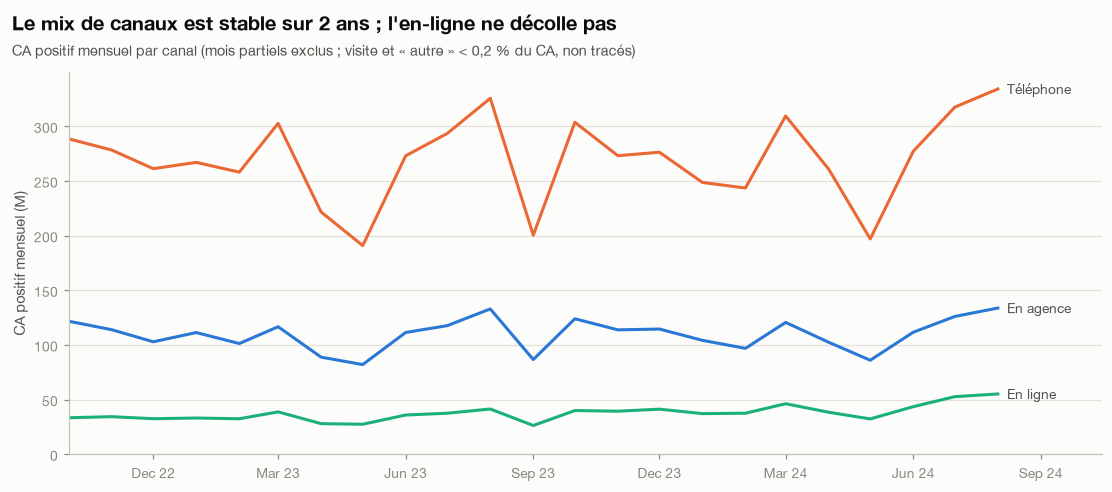

In [11]:
monthly_ch = q("""
SELECT date_trunc('month', date_order) AS m, order_channel, sum(greatest(sales_net, 0)) AS ca
FROM sales GROUP BY 1, 2 ORDER BY 1""")
monthly_ch = monthly_ch[(monthly_ch["m"] > "2022-09-30") & (monthly_ch["m"] < "2024-09-01")]
piv = monthly_ch.pivot(index="m", columns="order_channel", values="ca")[order]
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
for col in ["by phone", "at the store", "online"]:
    ax.plot(piv.index, piv[col], color=CHANNEL_COLOR[col])
    label_end(ax, piv.index[-1], piv[col].iloc[-1], CHANNEL_LABEL[col])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_m))
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_xlim(piv.index[0], piv.index[-1] + pd.Timedelta(days=75))
ax.set_ylabel("CA positif mensuel (M)")
headline(fig, "Le mix de canaux est stable sur 2 ans ; l'en-ligne ne décolle pas",
         "CA positif mensuel par canal (mois partiels exclus ; visite et « autre » < 0,2 % du CA, non tracés)")
plt.show()

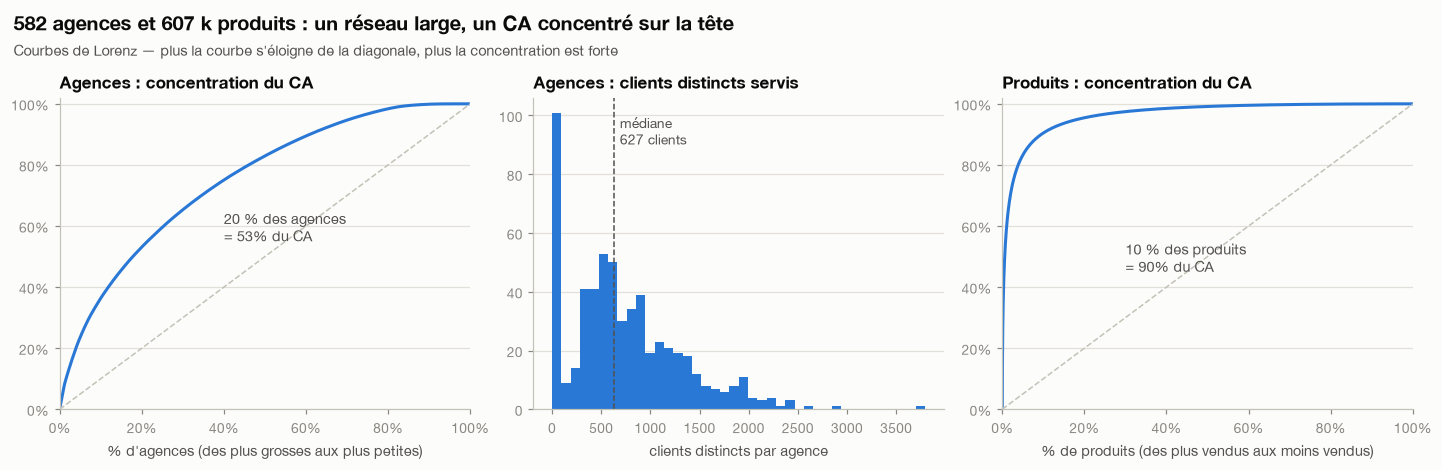

In [12]:
br = q("""
SELECT branch_id, sum(greatest(sales_net, 0)) AS ca, count(DISTINCT client_id) AS clients
FROM sales GROUP BY 1 ORDER BY ca DESC""")
br["cum_ca"] = br["ca"].cumsum() / br["ca"].sum()
br["rank_share"] = np.arange(1, len(br) + 1) / len(br)
prod = q("""
SELECT product_id, sum(greatest(sales_net, 0)) AS ca FROM sales GROUP BY 1 ORDER BY ca DESC""")
prod["cum_ca"] = prod["ca"].cumsum() / prod["ca"].sum()
prod["rank_share"] = np.arange(1, len(prod) + 1) / len(prod)


def at(df, p):
    return df.loc[df["rank_share"] <= p, "cum_ca"].iloc[-1]


fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
axes[0].plot(br["rank_share"], br["cum_ca"], color=C["blue"])
axes[0].plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
axes[0].set_title("Agences : concentration du CA")
axes[0].set_xlabel("% d'agences (des plus grosses aux plus petites)")
axes[0].text(0.4, 0.55, f"20 % des agences\n= {at(br, 0.2):.0%} du CA", fontsize=9.5, color=INK2)
axes[1].hist(br["clients"], bins=40, color=C["blue"])
axes[1].axvline(br["clients"].median(), color=INK2, lw=1, ls="--")
axes[1].text(br["clients"].median() * 1.1, axes[1].get_ylim()[1] * 0.85, f"médiane\n{br['clients'].median():,.0f} clients", fontsize=9, color=INK2)
axes[1].set_title("Agences : clients distincts servis")
axes[1].set_xlabel("clients distincts par agence")
axes[1].grid(axis="x", visible=False)
axes[2].plot(prod["rank_share"], prod["cum_ca"], color=C["blue"])
axes[2].plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
axes[2].set_title("Produits : concentration du CA")
axes[2].set_xlabel("% de produits (des plus vendus aux moins vendus)")
axes[2].text(0.3, 0.45, f"10 % des produits\n= {at(prod, 0.1):.0%} du CA", fontsize=9.5, color=INK2)
for ax in (axes[0], axes[2]):
    pct_axis(ax)
    pct_axis(ax, "x")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
headline(fig, f"{kpi['agences']:,.0f} agences et {kpi['produits'] / 1e3:,.0f} k produits : un réseau large, un CA concentré sur la tête",
         "Courbes de Lorenz — plus la courbe s'éloigne de la diagonale, plus la concentration est forte")
plt.show()

**Lecture** : ~**100 des 582 « agences » servent moins de 50 clients** (alors que la médiane est de ~630) tout en réalisant ~120 M de CA, quasi exclusivement **par téléphone**. Ce ne sont probablement pas des points de vente physiques (centres d'appels, comptes clés centralisés ?). Un client est aussi **rarement fidèle à une seule agence** (notebook `02_clients_rhythm_and_churn_definition`) : l'agence est un attribut fragile pour piloter le churn. À confirmer avec la Data team.